# Notebook 03: Results, figures and answers to the research questions

CSC790 Deep Learning project, Topic 3: *Deep Neural Networks for Semantic Sentiment Analysis in Code-Mixed English-Yorùbá Social Media Conversations*.

This notebook needs no GPU. It reads the saved test predictions of all 30 training runs (6 models × 5 seeds, produced by Notebook 02), the code-mixing annotations made by the two team members, and the AfriSenti Yorùbá test set. It then:

1. compares the six architectures (research question 2),
2. reports how common code-mixing is and whether it lowers accuracy (research question 1),
3. tests whether contextual models handle proverbs, idioms and praise poetry better (research question 3),
4. shows what the BiLSTM's attention focuses on, and
5. saves every figure used in the report to `results/figures/`.

In [1]:
import os, csv, glob, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix

ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
FIG = os.path.join(ROOT, "results", "figures"); os.makedirs(FIG, exist_ok=True)
LABS = ["negative", "neutral", "positive"]
MODELS = ["lstm", "bilstm_attn", "mbert", "xlmr_base", "afriberta_large", "afroxlmr_large"]
NAME = {"lstm": "LSTM", "bilstm_attn": "BiLSTM + attention", "mbert": "mBERT", "xlmr_base": "XLM-R base",
        "afriberta_large": "AfriBERTa-large", "afroxlmr_large": "AfroXLMR-large"}
FAMILY = {"lstm": "Recurrent (trained from scratch)", "bilstm_attn": "Recurrent (trained from scratch)",
          "mbert": "General multilingual transformer", "xlmr_base": "General multilingual transformer",
          "afriberta_large": "Africa-centric transformer", "afroxlmr_large": "Africa-centric transformer"}
COL = {"Recurrent (trained from scratch)": "#2a78d6", "General multilingual transformer": "#eb6834",
       "Africa-centric transformer": "#1baf7a"}
plt.rcParams.update({"font.family": "serif", "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.6, "axes.axisbelow": True,
                     "savefig.dpi": 200, "savefig.bbox": "tight"})

# test set with the same ids as Notebook 01 (test ids start after train + dev)
path = os.path.join(ROOT, "data", "raw", "test.tsv")
if not os.path.exists(path):
    import subprocess, sys; subprocess.run([sys.executable, os.path.join(ROOT, "data", "download_afrisenti.py")], check=True)
test = pd.read_csv(path, sep="\t", quoting=csv.QUOTE_NONE, on_bad_lines="skip")
test["tweet"] = test.tweet.astype(str).str.replace('"', "", regex=False).str.strip()
test["id"] = [f"yor_{10612 + i:05d}" for i in range(len(test))]
test = test.set_index("id")

preds = {m: [pd.read_csv(f).set_index("id").loc[test.index] for f in sorted(glob.glob(os.path.join(ROOT, "results", "preds", f"{m}_seed*_test.csv")))] for m in MODELS}
y = test.label.map(LABS.index).values
P = {m: np.stack([d.pred.map(LABS.index).values for d in preds[m]]) for m in MODELS}
VOTE = {m: np.array([np.bincount(P[m][:, i], minlength=3).argmax() for i in range(len(y))]) for m in MODELS}
print("Test tweets:", len(test), "| runs per model:", {m: len(preds[m]) for m in MODELS})

Test tweets: 4515 | runs per model: {'lstm': 5, 'bilstm_attn': 5, 'mbert': 5, 'xlmr_base': 5, 'afriberta_large': 5, 'afroxlmr_large': 5}


## 1. Which architecture performs best? (research question 2)

In [2]:
rows = []
for m in MODELS:
    w = [f1_score(y, P[m][k], average="weighted") * 100 for k in range(5)]
    mac = [f1_score(y, P[m][k], average="macro") * 100 for k in range(5)]
    acc = [accuracy_score(y, P[m][k]) * 100 for k in range(5)]
    rows.append({"model": NAME[m], "family": FAMILY[m], "weighted_F1": np.mean(w), "sd": np.std(w, ddof=1),
                 "macro_F1": np.mean(mac), "accuracy": np.mean(acc)})
overall = pd.DataFrame(rows).set_index("model")
overall.round(2)

,family,weighted_F1,sd,macro_F1,accuracy
model,,,,,
LSTM,Recurrent (trained from scratch),67.83,0.42,65.93,67.21
BiLSTM + attention,Recurrent (trained from scratch),67.19,1.36,65.29,66.60
mBERT,General multilingual transformer,63.63,1.66,61.80,64.44
XLM-R base,General multilingual transformer,61.68,2.88,59.63,61.81
AfriBERTa-large,Africa-centric transformer,72.47,0.54,70.70,72.19
AfroXLMR-large,Africa-centric transformer,73.61,0.79,71.91,73.36


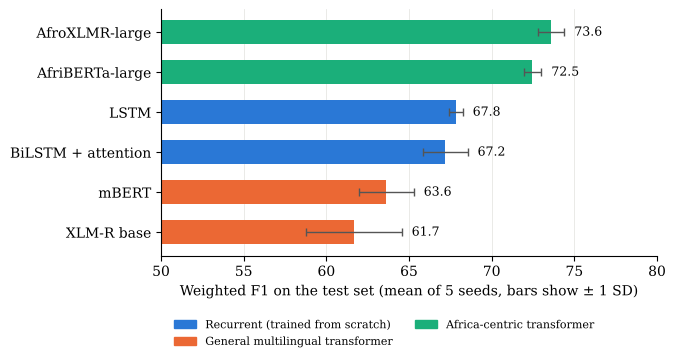

In [3]:
o = overall.sort_values("weighted_F1")
fig, ax = plt.subplots(figsize=(6.4, 3.2))
ax.barh(o.index, o.weighted_F1, xerr=o.sd, color=[COL[f] for f in o.family], height=0.6,
        error_kw=dict(ecolor="#555", lw=1, capsize=3))
for i, (v, s) in enumerate(zip(o.weighted_F1, o.sd)):
    ax.text(v + s + 0.6, i, f"{v:.1f}", va="center", fontsize=9)
ax.set_xlim(50, 80); ax.set_xlabel("Weighted F1 on the test set (mean of 5 seeds, bars show ± 1 SD)")
ax.grid(axis="y", visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in COL.values()]
ax.legend(handles, COL.keys(), loc="upper center", bbox_to_anchor=(0.45, -0.22), ncol=2, fontsize=8, frameon=False)
fig.savefig(os.path.join(FIG, "fig1_model_comparison.png")); plt.show()

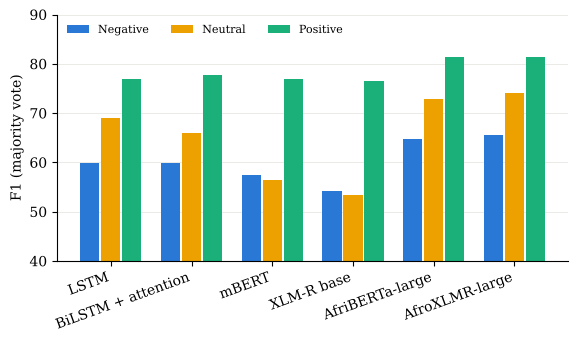

,negative,neutral,positive
LSTM,59.9,69.0,76.9
BiLSTM + attention,60.0,66.0,77.7
mBERT,57.5,56.5,76.9
XLM-R base,54.3,53.3,76.5
AfriBERTa-large,64.8,72.9,81.4
AfroXLMR-large,65.5,74.0,81.3


In [4]:
# per-class F1 of the majority vote over the five seeds
pc = pd.DataFrame({NAME[m]: f1_score(y, VOTE[m], average=None) * 100 for m in MODELS}, index=LABS).T
fig, ax = plt.subplots(figsize=(6.6, 3.2))
x = np.arange(len(pc)); wbar = 0.26
for j, (lab, c) in enumerate(zip(LABS, ["#2a78d6", "#eda100", "#1baf7a"])):
    ax.bar(x + (j - 1) * wbar, pc[lab], width=wbar - 0.02, color=c, label=lab.capitalize())
ax.set_xticks(x); ax.set_xticklabels(pc.index, rotation=20, ha="right"); ax.set_ylim(40, 90)
ax.set_ylabel("F1 (majority vote)"); ax.grid(axis="x", visible=False); ax.legend(frameon=False, ncol=3, fontsize=8, loc="upper left")
fig.savefig(os.path.join(FIG, "fig2_per_class_f1.png")); plt.show()
pc.round(1)

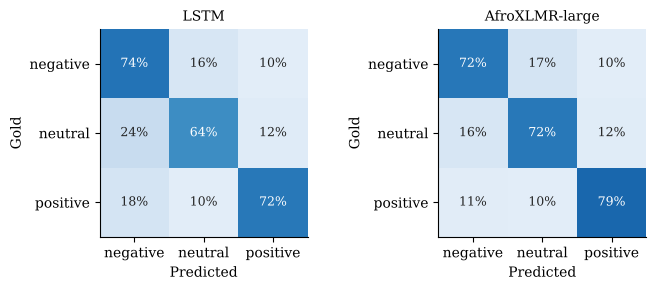

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(7, 3))
for ax, m in zip(axes, ["lstm", "afroxlmr_large"]):
    cm = confusion_matrix(y, VOTE[m], normalize="true") * 100
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=100)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{cm[i, j]:.0f}%", ha="center", va="center", color="white" if cm[i, j] > 55 else "#222", fontsize=9)
    ax.set_xticks(range(3)); ax.set_yticks(range(3)); ax.set_xticklabels(LABS); ax.set_yticklabels(LABS)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Gold"); ax.set_title(NAME[m], fontsize=10); ax.grid(False)
fig.tight_layout(); fig.savefig(os.path.join(FIG, "fig3_confusion_matrices.png")); plt.show()

## 2. How common is code-mixing, and does it lower accuracy? (research question 1)

Candidate tweets (CMI > 0): 1978 | audited zero-score tweets: 400 | mixed among audited: 0
Share of the whole test set that is code-mixed: 6.0%


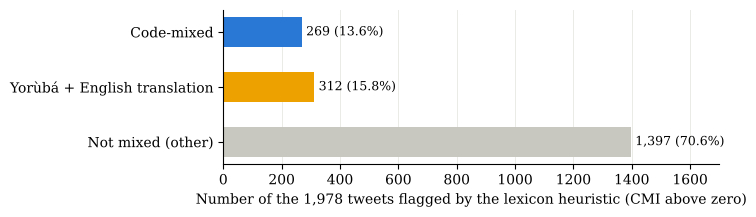

Code-mixed                       269
Yorùbá + English translation     312
Not mixed (other)               1397
dtype: int64

In [6]:
lay = pd.read_csv(os.path.join(ROOT, "data", "annotations", "afrisenti_yor_test_codemixing_v1.csv")).set_index("id")
s1 = lay[lay.sampling_group == "S1_candidate"]
comp = pd.Series({"Code-mixed": int((s1.is_codemixed == 1).sum()),
                  "Yorùbá + English translation": int(s1.translation_pair.sum()),
                  "Not mixed (other)": int(((s1.is_codemixed == 0) & (s1.translation_pair == 0)).sum())})
print("Candidate tweets (CMI > 0):", len(s1), "| audited zero-score tweets:", (lay.sampling_group == "S0_audit").sum(),
      "| mixed among audited:", int(lay[lay.sampling_group == "S0_audit"].is_codemixed.sum()))
print("Share of the whole test set that is code-mixed: {:.1%}".format(comp["Code-mixed"] / len(test)))
fig, ax = plt.subplots(figsize=(6.4, 2.0))
order = comp.iloc[::-1]
ax.barh(order.index, order.values, color=["#c9c8c0", "#eda100", "#2a78d6"], height=0.55)
for i, v in enumerate(order.values): ax.text(v + 15, i, f"{v:,} ({v / len(s1):.1%})", va="center", fontsize=9)
ax.set_xlim(0, 1700); ax.set_xlabel(f"Number of the {len(s1):,} tweets flagged by the lexicon heuristic (CMI above zero)"); ax.grid(axis="y", visible=False)
fig.savefig(os.path.join(FIG, "fig4_annotation_outcome.png")); plt.show()
comp

In [7]:
mixed = test.index.isin(lay.index[lay.is_codemixed == 1])
rng = np.random.default_rng(11)
im, inn = np.where(mixed)[0], np.where(~mixed)[0]
rows = []
for m in MODELS:
    gm = np.mean([f1_score(y[mixed], P[m][k][mixed], average="weighted") for k in range(5)]) * 100
    gn = np.mean([f1_score(y[~mixed], P[m][k][~mixed], average="weighted") for k in range(5)]) * 100
    boots = []
    for _ in range(2000):
        a = rng.choice(im, len(im)); b = rng.choice(inn, len(inn))
        boots.append((f1_score(y[a], VOTE[m][a], average="weighted") - f1_score(y[b], VOTE[m][b], average="weighted")) * 100)
    rows.append({"model": NAME[m], "mixed": gm, "other": gn, "gap": gm - gn,
                 "ci_low": np.percentile(boots, 2.5), "ci_high": np.percentile(boots, 97.5)})
cm_tab = pd.DataFrame(rows).set_index("model")
cm_tab.round(1)

,mixed,other,gap,ci_low,ci_high
model,,,,,
LSTM,63.6,68.1,-4.5,-9.7,1.9
BiLSTM + attention,62.5,67.5,-4.9,-9.1,2.6
mBERT,59.2,63.9,-4.7,-10.5,1.7
XLM-R base,64.8,61.5,3.3,-3.2,9.1
AfriBERTa-large,71.3,72.5,-1.3,-5.5,5.0
AfroXLMR-large,73.2,73.6,-0.4,-5.5,5.3


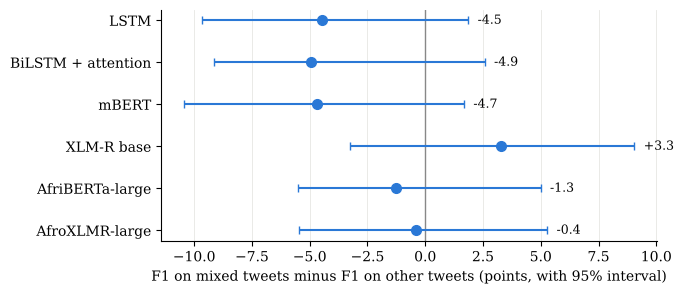

In [8]:
t = cm_tab.iloc[::-1]
fig, ax = plt.subplots(figsize=(6.4, 3))
ax.axvline(0, color="#888", lw=1)
ax.errorbar(t.gap, range(len(t)), xerr=[t.gap - t.ci_low, t.ci_high - t.gap], fmt="o", color="#2a78d6",
            ecolor="#2a78d6", elinewidth=1.5, capsize=3, markersize=7)
for i, g in enumerate(t.gap): ax.text(t.ci_high.iloc[i] + 0.4, i, f"{g:+.1f}", va="center", fontsize=9)
ax.set_yticks(range(len(t))); ax.set_yticklabels(t.index); ax.grid(axis="y", visible=False)
ax.set_xlabel("F1 on mixed tweets minus F1 on other tweets (points, with 95% interval)")
fig.savefig(os.path.join(FIG, "fig5_codemixing_gap.png")); plt.show()

## 3. Do contextual models understand local expressions and idioms better? (research question 3)

We take the tweets that explicitly talk about a proverb, idiom, saying, praise poem or the meaning of an expression (keywords such as *òwe*, *proverb*, *oríkì*, *idiom*, *ìtumọ̀*). This is a transparent but rough way to find local expressions; Chapter Five lists it as a limitation.

In [9]:
pat = r"proverb|\bòwe\b|\bowe\b|oríkì|\boriki\b|idiom|\bsaying\b|wisdom|ìtumọ̀|itumo"
idi = test.tweet.str.lower().str.contains(pat).values
print("Local-expression tweets:", idi.sum(), test[idi].label.value_counts().to_dict())
rows = []
for m in MODELS:
    a = np.mean([f1_score(y[idi], P[m][k][idi], average="weighted") for k in range(5)]) * 100
    b = np.mean([f1_score(y[~idi], P[m][k][~idi], average="weighted") for k in range(5)]) * 100
    rows.append({"model": NAME[m], "local_expressions": a, "other_tweets": b, "drop": b - a})
idi_tab = pd.DataFrame(rows).set_index("model")
# does the advantage of the best contextual model over the LSTM grow on local expressions?
ii, oo = np.where(idi)[0], np.where(~idi)[0]
dd = []
for _ in range(2000):
    a = rng.choice(ii, len(ii)); b = rng.choice(oo, len(oo))
    adv_i = f1_score(y[a], VOTE["afroxlmr_large"][a], average="weighted") - f1_score(y[a], VOTE["lstm"][a], average="weighted")
    adv_o = f1_score(y[b], VOTE["afroxlmr_large"][b], average="weighted") - f1_score(y[b], VOTE["lstm"][b], average="weighted")
    dd.append((adv_i - adv_o) * 100)
print("AfroXLMR-large advantage over LSTM: extra {:.1f} points on local expressions (95% interval {:.1f} to {:.1f})".format(
      np.mean(dd), np.percentile(dd, 2.5), np.percentile(dd, 97.5)))
idi_tab.round(1)

Local-expression tweets: 86 {'neutral': 50, 'negative': 19, 'positive': 17}


AfroXLMR-large advantage over LSTM: extra 8.8 points on local expressions (95% interval -2.6 to 20.7)


,local_expressions,other_tweets,drop
model,,,
LSTM,53.0,68.1,15.2
BiLSTM + attention,54.5,67.4,12.9
mBERT,58.4,63.7,5.4
XLM-R base,56.3,61.8,5.5
AfriBERTa-large,62.9,72.7,9.8
AfroXLMR-large,67.6,73.7,6.1


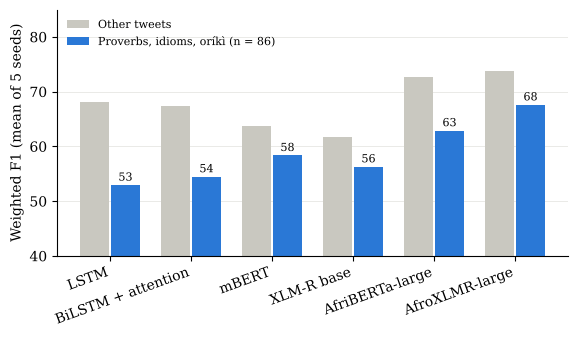

In [10]:
fig, ax = plt.subplots(figsize=(6.6, 3.2))
x = np.arange(len(idi_tab)); wbar = 0.38
ax.bar(x - wbar / 2, idi_tab.other_tweets, width=wbar - 0.02, color="#c9c8c0", label="Other tweets")
ax.bar(x + wbar / 2, idi_tab.local_expressions, width=wbar - 0.02, color="#2a78d6", label=f"Proverbs, idioms, oríkì (n = {idi.sum()})")
for i, v in enumerate(idi_tab.local_expressions): ax.text(i + wbar / 2, v + 0.8, f"{v:.0f}", ha="center", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(idi_tab.index, rotation=20, ha="right"); ax.set_ylim(40, 85)
ax.set_ylabel("Weighted F1 (mean of 5 seeds)"); ax.grid(axis="x", visible=False); ax.legend(frameon=False, fontsize=8, loc="upper left")
fig.savefig(os.path.join(FIG, "fig6_local_expressions.png")); plt.show()

## 4. What does the BiLSTM attend to?

In [11]:
att = preds["bilstm_attn"][0].join(test.tweet, rsuffix="_t")
show = ["yor_15008", "yor_11514", "yor_12083", "yor_14401", "yor_13603"]
att.loc[show, ["tweet", "label", "pred", "top_attention"]]

,tweet,label,pred,top_attention
id,,,,
yor_15008,owó epo léwó owó ọkọ̀ léwó,negative,negative,owó | ọkọ̀ | epo
yor_11514,mo fe alaafia fun venezuela jòwó jòwó jòwó èmi...,positive,positive,venezuela | alaafia | fun
yor_12083,àti pé ẹ̀rù kankan ò bàmí ilé baba kìí bọmọ lẹ́rù,positive,negative,kankan | ẹ̀rù | ò
yor_14401,ai fagba fẹni kan ni kojẹ kí ayé gun,negative,positive,gun | kí | ayé
yor_13603,ẹ jọ̀wọ́ kí ni pọ̀mọ́ ṣe o,neutral,positive,jọ̀wọ́ | ẹ | kí


## 5. Save the tables used in the report

In [12]:
out = os.path.join(ROOT, "results", "analysis"); os.makedirs(out, exist_ok=True)
overall.round(2).to_csv(os.path.join(out, "table_overall.csv")); pc.round(2).to_csv(os.path.join(out, "table_per_class.csv"))
cm_tab.round(2).to_csv(os.path.join(out, "table_codemixing_gap.csv")); idi_tab.round(2).to_csv(os.path.join(out, "table_local_expressions.csv"))
json.dump({"local_expr_n": int(idi.sum()), "afroxlmr_vs_lstm_extra_adv": [float(np.mean(dd)), float(np.percentile(dd, 2.5)), float(np.percentile(dd, 97.5))],
           "s1_composition": comp.to_dict()}, open(os.path.join(out, "course_extras.json"), "w"), indent=1)
print("saved figures:", sorted(os.listdir(FIG)))

saved figures: ['fig1_model_comparison.png', 'fig2_per_class_f1.png', 'fig3_confusion_matrices.png', 'fig4_annotation_outcome.png', 'fig5_codemixing_gap.png', 'fig6_local_expressions.png']
